# Churn: Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost
חיזוי עזיבת לקוחות (`Exited`). סדר הפעולות: עיבוד נתונים ← חלוקה 80/20 ← נרמול ← GridSearchCV עם 5-Fold ← אימון סופי ← הערכה.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

df = pd.read_csv('churn_modelling.csv')
print(df.shape)
print(df['Exited'].value_counts(normalize=True))
df.head()

(10000, 13)
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## שלב א: עיבוד הנתונים (לפני החלוקה)
בדיקת איכות, הסרת עמודות מזהות (`CustomerId`, `Surname`) וקידוד One-Hot של המשתנים הקטגוריים. הפעולות האלה לא "לומדות" שום דבר מהנתונים (כל שורה מעובדת לבד), ולכן בטוח לבצע אותן לפני החלוקה.

In [2]:
print('missing values:', df.isna().sum().sum(), '| duplicate rows:', df.duplicated().sum())

cat_cols = ['Geography', 'Gender']
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
            'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

data = df.drop(columns=['CustomerId', 'Surname'])
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)
X = data.drop(columns=['Exited'])
y = data['Exited']
X.head()

missing values: 0 | duplicate rows: 0


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


## שלב ב: חלוקה לאימון (80%) ולמבחן (20%)
חלוקה אקראית ומרובדת (`stratify=y`), כך ששיעור העוזבים זהה בשתי הקבוצות.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('train:', X_train.shape, f'churn {y_train.mean():.1%}', '| test:', X_test.shape, f'churn {y_test.mean():.1%}')

train: (8000, 11) churn 20.4% | test: (2000, 11) churn 20.3%


## שלב ג: נרמול (אחרי החלוקה)
`StandardScaler` מחשב ממוצע וסטיית תקן, ולכן הוא חייב להילמד מנתוני האימון בלבד, אחרת מידע מנתוני המבחן דולף לאימון. הוא נמצא בתוך ה-Pipeline, ולכן גם בכל קפל של ה-Cross-Validation הוא נלמד רק מקפלי האימון. עמודות ה-0/1 נשארות כמו שהן.

In [4]:
prep = ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')

## כוונון היפר-פרמטרים: GridSearchCV עם 5-Fold Cross-Validation
החיפוש רץ על נתוני האימון בלבד. כל צירוף מאומן 5 פעמים (בכל פעם קפל אחר משמש לבדיקה), ונבחר הצירוף עם ה-F1 הממוצע הגבוה ביותר. נתוני המבחן לא משתתפים בבחירה. (זמן ריצה: כ-5 דקות)

In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
neg_pos = round((y_train == 0).sum() / (y_train == 1).sum(), 2)

search_space = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, solver='liblinear'), {
        'clf__C': [0.01, 0.1, 1, 10, 100],
        'clf__l1_ratio': [0, 1],            # 0 = L2, 1 = L1
        'clf__class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1), {
        'clf__max_depth': [None, 6, 10, 14],
        'clf__min_samples_leaf': [1, 3, 5],
        'clf__max_features': ['sqrt', 0.5],
        'clf__class_weight': [None, 'balanced_subsample']}),
    'XGBoost': (XGBClassifier(random_state=42, n_jobs=1), {
        'clf__n_estimators': [100, 200, 300],
        'clf__max_depth': [3, 4, 5, 6],
        'clf__learning_rate': [0.03, 0.05, 0.1],
        'clf__subsample': [0.8, 1.0],
        'clf__scale_pos_weight': [1, neg_pos]}),
    'LightGBM': (LGBMClassifier(random_state=42, verbose=-1, n_jobs=1), {
        'clf__n_estimators': [100, 200, 300],
        'clf__num_leaves': [15, 31, 63],
        'clf__learning_rate': [0.03, 0.05, 0.1],
        'clf__min_child_samples': [20, 40],
        'clf__class_weight': [None, 'balanced']}),
    'CatBoost': (CatBoostClassifier(random_seed=42, verbose=0, thread_count=1, allow_writing_files=False), {
        'clf__iterations': [300, 600],
        'clf__depth': [4, 6, 8],
        'clf__learning_rate': [0.03, 0.1],
        'clf__auto_class_weights': [None, 'Balanced']}),
}

searches = {}
for name, (clf, grid) in search_space.items():
    gs = GridSearchCV(Pipeline([('prep', prep), ('clf', clf)]), grid, scoring='f1', cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    std = gs.cv_results_['std_test_score'][gs.best_index_]
    print(f'{name}: best CV F1 = {gs.best_score_:.3f} ± {std:.3f}')
    print('   ', {k.replace('clf__', ''): v for k, v in gs.best_params_.items()})

Logistic Regression: best CV F1 = 0.490 ± 0.020
    {'C': 0.01, 'class_weight': 'balanced', 'l1_ratio': 0}


Random Forest: best CV F1 = 0.623 ± 0.025
    {'class_weight': 'balanced_subsample', 'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 5}


XGBoost: best CV F1 = 0.614 ± 0.018
    {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 300, 'scale_pos_weight': np.float64(3.91), 'subsample': 0.8}


LightGBM: best CV F1 = 0.617 ± 0.012
    {'class_weight': 'balanced', 'learning_rate': 0.1, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 31}


C:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
60 fits failed out of a total of 120.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\USER\AppData\L

CatBoost: best CV F1 = 0.619 ± 0.019
    {'auto_class_weights': 'Balanced', 'depth': 4, 'iterations': 600, 'learning_rate': 0.03}


## המודלים הסופיים
כל מודל מאומן מחדש על כל נתוני האימון עם הפרמטרים הטובים ביותר (GridSearchCV עושה זאת אוטומטית: `best_estimator_`).

In [6]:
models = {name: gs.best_estimator_ for name, gs in searches.items()}

## השוואה לפי מדדים

In [7]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba),
                 'Train Accuracy': m.score(X_train, y_train)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train Accuracy
Model,,,,,,
Logistic Regression,0.712,0.388,0.717,0.504,0.778,0.710
Random Forest,0.849,0.625,0.646,0.635,0.864,0.921
XGBoost,0.818,0.539,0.713,0.614,0.859,0.886
LightGBM,0.816,0.535,0.727,0.617,0.862,0.894
CatBoost,0.807,0.518,0.757,0.615,0.873,0.836


## מטריצות בלבול

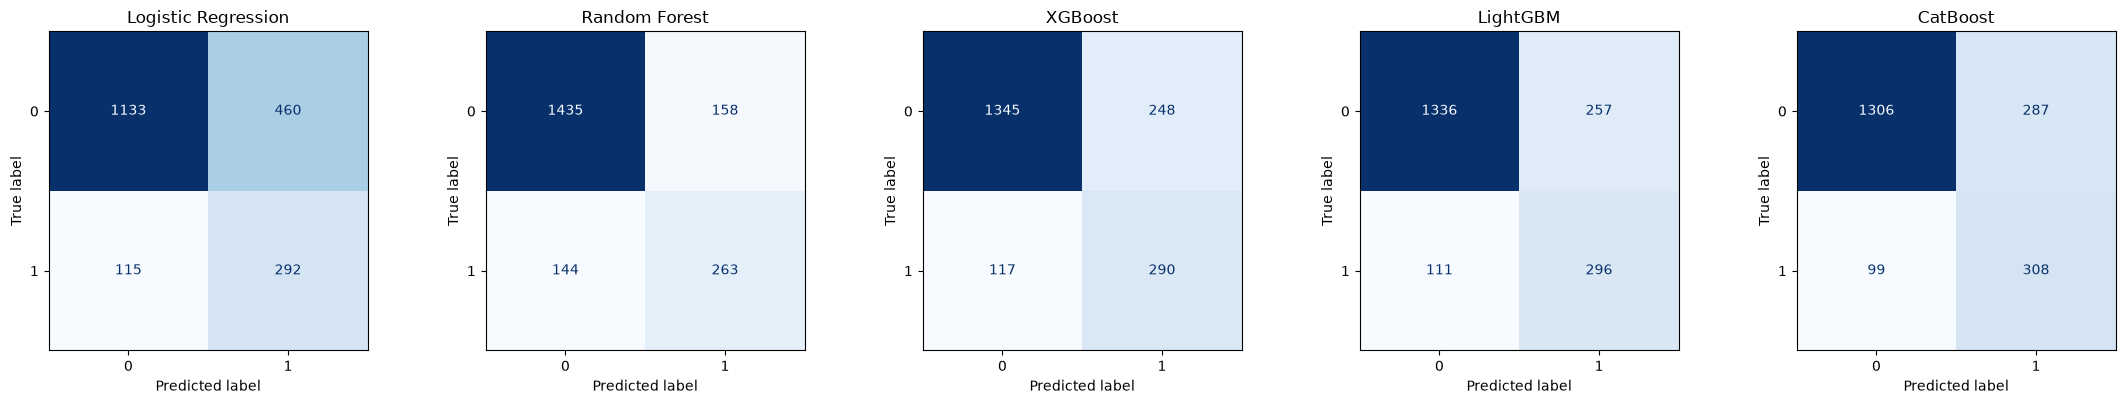

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## עקומות ROC

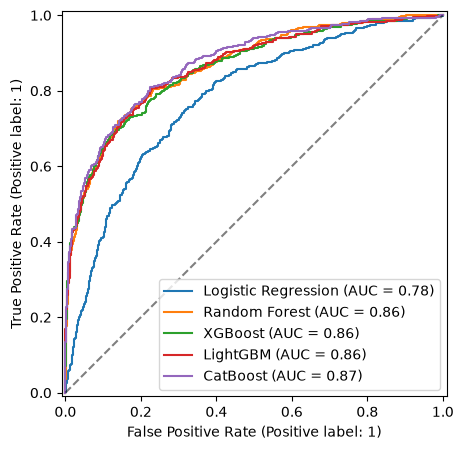

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.show()

## חשיבות משתנים (מודלי העצים)

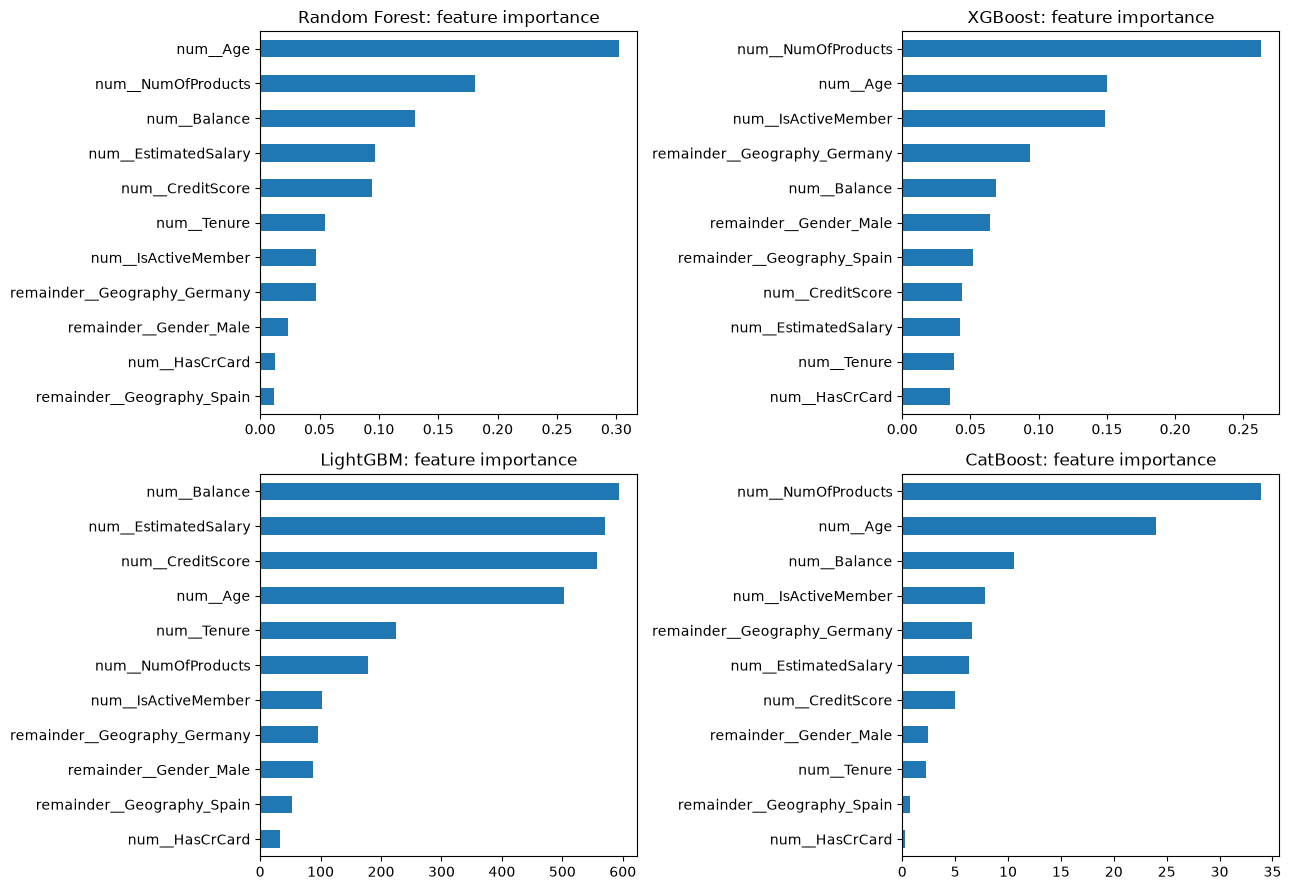

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()
for ax, name in zip(axes, ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']):
    m = models[name]
    names = m.named_steps['prep'].get_feature_names_out()
    imp = pd.Series(m.named_steps['clf'].feature_importances_, index=names).sort_values()
    imp.plot.barh(ax=ax, title=f'{name}: feature importance')
plt.tight_layout(); plt.show()